# 02 — Dataset construction

Steps 2–4 of the report (§6, §7): fix the time conventions and units, build a regular hourly grid, aggregate to valid days,
and compute lag/rolling features on the daily grid. All transformations are in `src/preprocessing.py`; the command-line
equivalent of this notebook is `uv run python src/build_dataset.py`.

Stations (chosen in notebook 01): **7441 US Embassy** (main) and **2161292 Chi cục BVMT** (secondary, the Kaggle source).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotting import apply_style, save, SERIES, TEXT_2, MODEL_COLORS, SEQ_CMAP
apply_style()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 60)
import json
from openmeteo import fetch_weather
from preprocessing import clean_hourly_pm25, daily_mean, daily_weather, build_features, assert_no_future_leak
import build_dataset

STATIONS = {7441: "US Embassy", 2161292: "Chi cục BVMT"}
raw = pd.read_parquet(ROOT / "data/interim/openaq_pm25_raw.parquet")
meta = pd.read_csv(ROOT / "data/interim/openaq_locations.csv").set_index("location_id")

## 1. Time conventions (report §7 step 2)

**OpenAQ.** Each record carries an explicit UTC offset (`+07:00` for Hanoi), so no guess is needed. By OpenAQ convention
the timestamp is the **end** of the averaging period. We convert to UTC, shift by the period length (1 h here), and label each
value by the start of its hour. A local day D then holds the hours that start between 00:00 and 23:00.

In [2]:
raw[raw.location_id == 7441][["location", "datetime", "datetime_utc", "parameter", "units", "value"]].head(3)

,location,datetime,datetime_utc,parameter,units,value
430220,Hanoi-7441,2016-11-10T00:00:00+07:00,2016-11-09 17:00:00+00:00,pm25,µg/m³,14.4
430221,Hanoi-7441,2016-11-10T01:00:00+07:00,2016-11-09 18:00:00+00:00,pm25,µg/m³,16.2
430222,Hanoi-7441,2016-11-10T02:00:00+07:00,2016-11-09 19:00:00+00:00,pm25,µg/m³,17.5


**Open-Meteo** is requested with `timezone=GMT` and `wind_speed_unit=ms`. To check the conversion, the mean diurnal cycle in
local time should put the temperature minimum near sunrise and the maximum in the early afternoon. PM2.5 at an urban site
should show traffic peaks in the morning and evening.

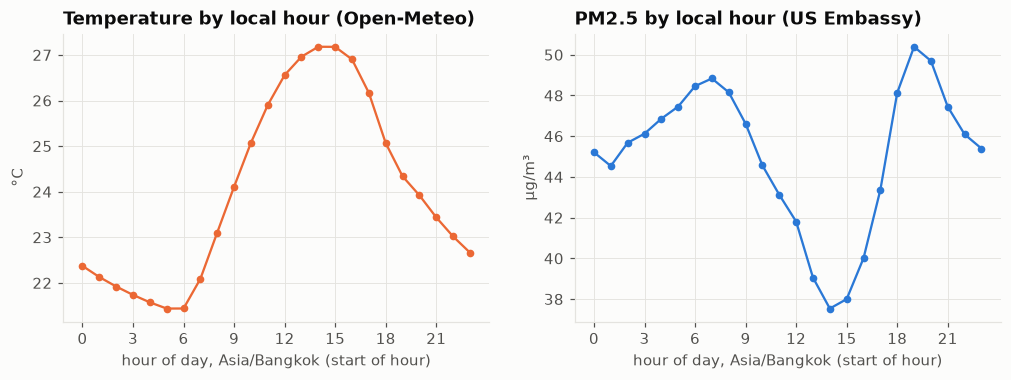

temperature min / max at local hour: 5 / 14


In [3]:
loc = 7441
hourly, rep = clean_hourly_pm25(raw[raw.location_id == loc])
w = fetch_weather(meta.loc[loc, "lat"], meta.loc[loc, "lon"],
                  (hourly.index.min() - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                  (hourly.index.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                  raw_path=ROOT / f"data/raw/openmeteo/weather_{loc}_{(hourly.index.min() - pd.Timedelta(days=1)):%Y-%m-%d}_{(hourly.index.max() + pd.Timedelta(days=1)):%Y-%m-%d}.json")
h = hourly.to_frame().join(w)
h.index = h.index.tz_convert("Asia/Bangkok")
prof = h.groupby(h.index.hour)[["pm25", "temperature_2m"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(prof.index, prof["temperature_2m"], color=SERIES[1], marker="o", ms=4)
axes[0].set_title("Temperature by local hour (Open-Meteo)"); axes[0].set_ylabel("°C")
axes[1].plot(prof.index, prof["pm25"], color=SERIES[0], marker="o", ms=4)
axes[1].set_title("PM2.5 by local hour (US Embassy)"); axes[1].set_ylabel("µg/m³")
for ax in axes: ax.set_xlabel("hour of day, Asia/Bangkok (start of hour)"); ax.set_xticks(range(0, 24, 3))
save(fig, "02_diurnal_cycles", ROOT)
print("temperature min / max at local hour:", prof.temperature_2m.idxmin(), "/", prof.temperature_2m.idxmax())

The temperature minimum falls around 05–06 h and the maximum around 13–14 h local time. PM2.5 peaks in the morning and in the
evening, when traffic is heavy and the boundary layer is shallow. Both cycles are consistent with correct UTC → local conversion.

### Wind-speed unit in the Kaggle file

The Kaggle dictionary says m/s, but its mean is 9.1 (report §4). We compare it with Open-Meteo wind in m/s at the same hours:

In [4]:
k = pd.read_csv(ROOT / "data/kaggle-hanoi_air_quality/hanoi_aqi_ml_ready_fixed.csv", parse_dates=["datetime"])
wk = fetch_weather(21.0152, 105.7999, "2024-02-13", "2026-01-27",
                   raw_path=ROOT / "data/raw/openmeteo/weather_kaggle_check.json")
kk = k.set_index(k["datetime"].dt.tz_localize("UTC"))[["wind_speed", "temperature"]]
j = kk.join(wk[["wind_speed_10m", "temperature_2m"]], how="inner").dropna()
print(f"mean Kaggle wind = {j.wind_speed.mean():.2f}, mean Open-Meteo wind (m/s) = {j.wind_speed_10m.mean():.2f}, "
      f"ratio = {j.wind_speed.mean() / j.wind_speed_10m.mean():.2f}  (km/h ÷ m/s = 3.6)")
for lag in (-7, 0, 7):
    jj = kk.shift(lag, freq="h").join(wk[["temperature_2m"]], how="inner").dropna()
    print(f"Kaggle temperature vs Open-Meteo, shift {lag} h: r = {jj.temperature.corr(jj.temperature_2m):.3f}")

mean Kaggle wind = 9.10, mean Open-Meteo wind (m/s) = 2.43, ratio = 3.75  (km/h ÷ m/s = 3.6)
Kaggle temperature vs Open-Meteo, shift -7 h: r = 0.996
Kaggle temperature vs Open-Meteo, shift 0 h: r = 0.728
Kaggle temperature vs Open-Meteo, shift 7 h: r = 0.617


* The ratio is close to 3.6, so **the Kaggle wind speed is in km/h**, not m/s.
* The Kaggle temperature matches Open-Meteo almost perfectly (r ≈ 0.996) only when shifted by −7 h. Its **weather columns
  are therefore in local time**, while its PM2.5 timestamps are in UTC (notebook 01). Inside the Kaggle file, weather and
  PM2.5 are joined 7 hours apart, which explains the 14:00 temperature peak in the report.

We do not use the Kaggle weather columns: our own Open-Meteo download is in m/s and on the same UTC time base as PM2.5.

## 2. Hourly cleaning and regular grid

Rules (`clean_hourly_pm25`): remove the AirNow sentinel −999 and other negative values, values above 1,000 µg/m³, duplicates
(averaged), and runs of ≥ 12 identical consecutive values (frozen sensor). Missing hours stay **NaN**, with no interpolation.

In [5]:
reports = {}
for loc in STATIONS:
    reports[loc] = build_dataset.build_station(loc, raw, meta)
pd.DataFrame(reports).T[["name", "raw_records", "negative_or_sentinel", "above_max", "duplicates_merged", "stuck_values",
                         "grid_hours", "valid_hours", "coverage", "days_total", "days_valid", "days_excluded",
                         "first_day", "last_day"]]

,name,raw_records,negative_or_sentinel,above_max,duplicates_merged,stuck_values,grid_hours,valid_hours,coverage,days_total,days_valid,days_excluded,first_day,last_day
7441,Hanoi,59387,8360,0,0,0,73751,51027,0.691882,3074,2080,994,2016-11-09,2025-04-09
2161292,Chi cục Bảo vệ Môi trường,17175,57,0,0,0,24218,17118,0.70683,1010,646,364,2024-01-29,2026-11-03


## 3. Daily aggregation: valid days (≥ 18 of 24 h) and excluded days

In [6]:
daily = {loc: pd.read_csv(ROOT / f"data/processed/station_{loc}_daily.csv", index_col=0, parse_dates=True) for loc in STATIONS}
for loc, d in daily.items():
    ex = d[~d.valid]
    print(f"{loc} {STATIONS[loc]}: {len(d)} days, {d.valid.sum()} valid, {len(ex)} excluded "
          f"({(ex.n_hours == 0).sum()} with no data at all, {((ex.n_hours > 0) & (ex.n_hours < 18)).sum()} partial)")

d = daily[7441]
by_year = pd.DataFrame({"valid": d.valid.groupby(d.index.year).sum(), "excluded": (~d.valid).groupby(d.index.year).sum()})
by_year

7441 US Embassy: 3074 days, 2080 valid, 994 excluded (763 with no data at all, 231 partial)
2161292 Chi cục BVMT: 1010 days, 646 valid, 364 excluded (153 with no data at all, 211 partial)


,valid,excluded
date,,
2016,47,6
2017,289,76
2018,240,125
2019,209,156
2020,333,33
2021,205,160
2022,128,237
2023,233,132
2024,302,64


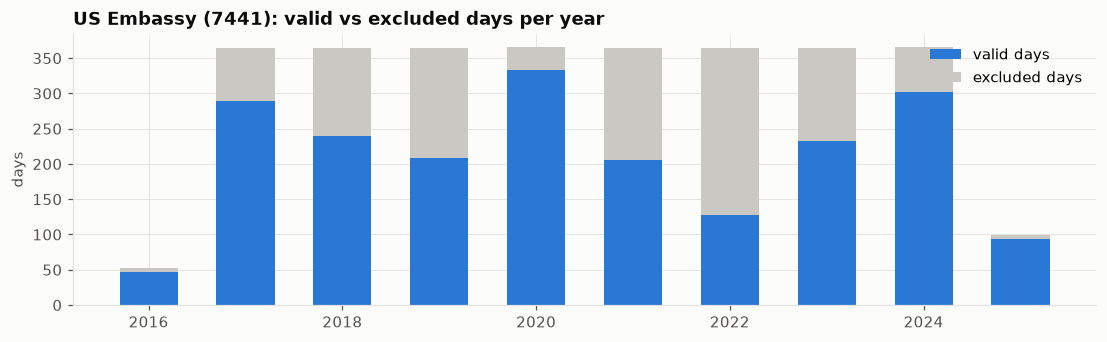

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(by_year.index, by_year["valid"], color=SERIES[0], width=0.6, label="valid days")
ax.bar(by_year.index, by_year["excluded"], bottom=by_year["valid"], color="#c9c8c2", width=0.6, label="excluded days")
ax.set_title("US Embassy (7441): valid vs excluded days per year"); ax.set_ylabel("days"); ax.legend(loc="upper right")
save(fig, "02_valid_days_per_year", ROOT)

## 4. Features (on the daily grid)

For an **issue day t** (forecast made at the end of day t) and **target = mean PM2.5 of day t+1**:

| Group | Features |
|---|---|
| PM2.5 history | `pm25_lag0` (today) … `pm25_lag6`, 3-day and 7-day rolling means, 7-day std, day-to-day change |
| Same-day weather (day t) | temperature mean/min/max/range, relative humidity, dew point, precipitation sum, surface and MSL pressure, 24 h pressure change, wind speed mean/max, wind u/v components, cloud cover, boundary-layer height mean/min |
| Calendar | month, day of week, weekend flag, day-of-year sin/cos, dry-season flag, Tết period (±7 days around the first day of Tết) |

The lags are shifts by **calendar days** on the reindexed daily grid, not by rows. A missing day therefore stays missing in every
lag that points to it, which fixes the row-based misalignment found in the Kaggle file (report §4). The boundary-layer height is
added to the planned weather list because it measures the thermal inversions directly.

In [8]:
feats = {loc: pd.read_csv(ROOT / f"data/processed/station_{loc}_features.csv", index_col=0, parse_dates=["target_date"])
         for loc in STATIONS}
for f in feats.values(): f.index = pd.to_datetime(f.index)
f = feats[7441]
print(f.shape)
f.loc["2019-12-01":"2019-12-03"].T.head(40)

(3074, 37)


date,2019-12-01,2019-12-02,2019-12-03
pm25_lag0,59.083333,30.458333,59.708333
pm25_lag1,84.416667,59.083333,30.458333
pm25_lag2,61.75,84.416667,59.083333
pm25_lag3,49.875,61.75,84.416667
pm25_lag4,91.208333,49.875,61.75
pm25_lag5,76.583333,91.208333,49.875
pm25_lag6,77.333333,76.583333,91.208333
pm25_roll3,68.416667,57.986111,49.75
pm25_roll7,71.464286,64.767857,62.357143
pm25_std7,14.899634,21.075823,20.45505


### Leakage test: no feature uses future data (report §7 gate 4)

In [9]:
for loc in STATIONS:
    assert_no_future_leak(feats[loc], daily[loc]["pm25"])
    # every lag refers to a day <= t: check against a brute-force recomputation on 200 random rows
    rng = np.random.default_rng(0)
    pm = daily[loc]["pm25"]
    for t in rng.choice(feats[loc].index, 200):
        for kk in range(7):
            v, e = feats[loc].at[t, f"pm25_lag{kk}"], pm.get(t - pd.Timedelta(days=kk), np.nan)
            assert (np.isnan(v) and np.isnan(e)) or np.isclose(v, e)
        assert feats[loc].at[t, "target_date"] == t + pd.Timedelta(days=1)
    print(f"{loc}: leakage tests passed")

7441: leakage tests passed


2161292: leakage tests passed


### Rows available for modelling

In [10]:
for loc, f in feats.items():
    ok = f[["target", "pm25_lag0"]].notna().all(axis=1)
    print(f"{loc} {STATIONS[loc]}: {ok.sum()} day pairs (today and tomorrow valid), "
          f"{f.dropna().shape[0]} with all features complete, "
          f"{f.loc[ok, [c for c in f if c.startswith('pm25_lag')]].notna().all(axis=1).sum()} complete 8-day windows")

7441 US Embassy: 1918 day pairs (today and tomorrow valid), 1179 with all features complete, 1337 complete 8-day windows
2161292 Chi cục BVMT: 589 day pairs (today and tomorrow valid), 361 with all features complete, 448 complete 8-day windows


We keep every pair where both today and tomorrow are valid (1,918 for the US Embassy, against 566 in the Kaggle file). Older
lags that are missing are left as NaN: the tree models handle NaN natively, and for Ridge they are imputed inside the training
pipeline. Persistence only needs `pm25_lag0`, so all models are evaluated on exactly the same rows.

**Outputs** (`data/processed/`): `station_{id}_hourly.parquet`, `station_{id}_daily.csv`, `station_{id}_excluded_days.csv`,
`station_{id}_features.csv`, `station_{id}_report.json`.